# Complete NLP/ML Pipeline for Legal Contract Clause Analysis

This notebook is divided into clear, modular sections. The goal is to detect 41 distinct legal contract clauses and assign a heuristic risk score.

### Sections:
1. **Setup & Imports**
2. **Data Loading & Cleaning**
3. **Data Transformation (Multi-Label formatting using Vectorized Operations)**
4. **Exploratory Data Analysis (EDA)**
5. **Text Preprocessing & Data Splitting**
6. **Model Training & Evaluation (Unrolled Commands)**
7. **Inference & Risk Analysis Pipeline**
8. **Export Models**


## 1. Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import ast
import re
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
import time

from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report
from sklearn.preprocessing import MultiLabelBinarizer

warnings.filterwarnings('ignore')


## 2. Data Loading & Cleaning
In this section, we load the raw dataset and perform basic data cleaning.
- We check for and remove completely empty rows or duplicates.
- We identify the 41 clause columns using pandas string methods (no loops).


In [2]:
def load_and_clean_data(filepath):
    print("Loading data...")
    df = pd.read_csv(filepath)
    
    # 1. Basic Cleaning
    initial_shape = df.shape
    df = df.dropna(how='all') # drop fully empty rows
    df = df.drop_duplicates(subset=['source_file', 'filename']) # drop duplicate files
    print(f"Shape after cleaning: {df.shape} (from {initial_shape})")
    
    # 2. Identify Clause Columns (Vectorized, no loops)
    cols_series = pd.Series(df.columns)
    answer_mask = cols_series.str.endswith('_answer')
    answer_cols = cols_series[answer_mask]
    clause_cols = answer_cols.str.replace('_answer', '').tolist()
    
    print(f"Identified {len(clause_cols)} clause categories.")
    return df, clause_cols

df_raw, clause_cols = load_and_clean_data('CUAD_combined.csv')


Loading data...
Shape after cleaning: (510, 84) (from (510, 84))
Identified 41 clause categories.


## 3. Data Transformation (Multi-Label)
We flatten the wide dataset into individual text snippets using Pandas vectorized operations (`melt` and `explode`) instead of slow iterations.


In [3]:
def safe_literal_eval(val):
    if pd.isna(val) or val == '[]' or val == '':
        return []
    try:
        return ast.literal_eval(val)
    except:
        return []

def transform_to_multilabel(df, clause_cols):
    print("Extracting text snippets via pandas melt & explode...")
    
    # Keep document identifier (using index)
    df = df.copy()
    df['document_id'] = df.index
    
    # Melt the dataframe so we have one row per clause category per document
    df_melted = df.melt(id_vars=['document_id'], value_vars=clause_cols, var_name='clause_type', value_name='text_list')
    
    # Convert stringified lists to actual lists
    df_melted['text_list'] = df_melted['text_list'].apply(safe_literal_eval)
    
    # Explode the lists into individual rows (vectorized)
    df_snippets = df_melted.explode('text_list').dropna(subset=['text_list'])
    df_snippets = df_snippets[df_snippets['text_list'].str.strip() != '']
    df_snippets = df_snippets.rename(columns={'text_list': 'text'})
    
    print("Aggregating labels per snippet...")
    # Group by text to aggregate multiple labels per snippet
    df_multi = df_snippets.groupby(['document_id', 'text'])['clause_type'].apply(list).reset_index()
    
    # Use MultiLabelBinarizer for fast vectorized binary column generation
    mlb = MultiLabelBinarizer(classes=clause_cols)
    binary_labels = pd.DataFrame(mlb.fit_transform(df_multi['clause_type']), columns=mlb.classes_, index=df_multi.index)
    
    df_multi = pd.concat([df_multi, binary_labels], axis=1)
    
    print(f"Final Multilabel Dataset Shape: {df_multi.shape}")
    return df_multi

df_multi = transform_to_multilabel(df_raw, clause_cols)
df_multi.head(3)


Extracting text snippets via pandas melt & explode...
Aggregating labels per snippet...


Final Multilabel Dataset Shape: (11850, 44)


,document_id,text,clause_type,document_name,parties,agreement_date,effective_date,expiration_date,renewal_term,notice_period_to_terminate_renewal,...,source_code_escrow,post_termination_services,audit_rights,uncapped_liability,cap_on_liability,liquidated_damages,warranty_duration,insurance,covenant_not_to_sue,third_party_beneficiary
0,0,8th day of May 2014,[agreement_date],0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,BIRCH FIRST GLOBAL INVESTMENTS INC.,[parties],0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,COMPANY'S SOLE AND EXCLUSIVE LIABILITY FOR THE...,[cap_on_liability],0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


## 4. Exploratory Data Analysis (EDA)
We visualize the class distribution to understand if we need to handle class imbalance during modeling.


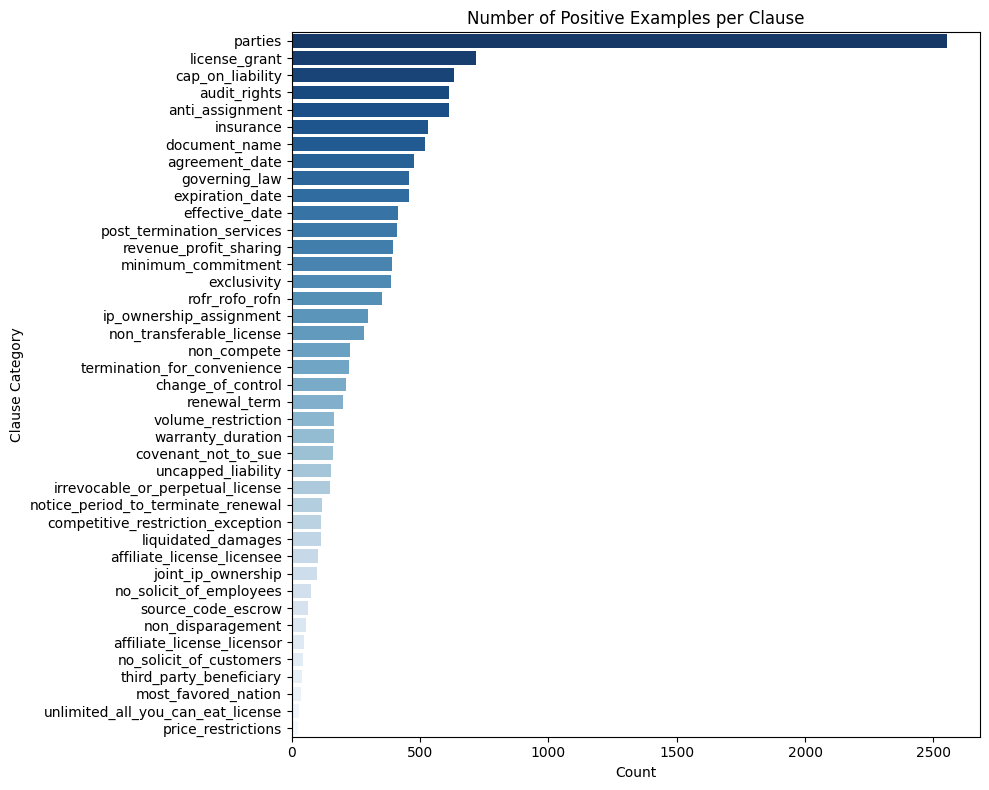

In [4]:
def plot_class_distribution(df, clause_cols):
    class_counts = df[clause_cols].sum().sort_values(ascending=False)
    
    plt.figure(figsize=(10, 8))
    sns.barplot(x=class_counts.values, y=class_counts.index, palette="Blues_r")
    plt.title("Number of Positive Examples per Clause")
    plt.xlabel("Count")
    plt.ylabel("Clause Category")
    plt.tight_layout()
    plt.show()

plot_class_distribution(df_multi, clause_cols)


## 5. Text Preprocessing & Data Splitting
We split the data by `document_id` to prevent data leakage. Then we clean the text using Pandas vectorized `.str.replace()`.


In [5]:
def clean_legal_text_vectorized(series):
    """
    Cleans a pandas series of legal text using vectorized operations.
    We do NOT remove stopwords because words like 'shall', 'may', and 'except' are critical in law.
    """
    cleaned = series.str.lower()
    cleaned = cleaned.str.replace(r'\\s+', ' ', regex=True) # Normalize whitespace
    cleaned = cleaned.str.replace(r'[^a-z0-9\\s.,;\-]', '', regex=True) # Keep basic punctuation
    return cleaned.str.strip()

def split_and_preprocess(df, clause_cols):
    print("Splitting dataset by contract...")
    gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
    train_idx, test_idx = next(gss.split(df, groups=df['document_id']))
    
    df_train = df.iloc[train_idx].copy()
    df_test = df.iloc[test_idx].copy()
    
    print("Applying text cleaning (vectorized)...")
    df_train['clean_text'] = clean_legal_text_vectorized(df_train['text'])
    df_test['clean_text'] = clean_legal_text_vectorized(df_test['text'])
    
    X_train, y_train = df_train['clean_text'], df_train[clause_cols].values
    X_test, y_test = df_test['clean_text'], df_test[clause_cols].values
    
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = split_and_preprocess(df_multi, clause_cols)


Splitting dataset by contract...
Applying text cleaning (vectorized)...


## 6. Model Training & Evaluation
We build a TF-IDF pipeline and evaluate 3 classical ML models. We execute separate unrolled commands for each model instead of looping.


In [6]:
def train_and_evaluate(X_train, X_test, y_train, y_test):
    print("Extracting TF-IDF Features...")
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95)
    X_train_vec = vectorizer.fit_transform(X_train)
    X_test_vec = vectorizer.transform(X_test)
    
    results = []
    trained_models = {}
    
    # 1. Train Logistic Regression
    print("Training Logistic Regression...")
    start_lr = time.time()
    model_lr = OneVsRestClassifier(LogisticRegression(class_weight='balanced', max_iter=1000))
    model_lr.fit(X_train_vec, y_train)
    preds_lr = model_lr.predict(X_test_vec)
    results.append({
        'Model': 'Logistic Regression',
        'Macro F1': f1_score(y_test, preds_lr, average='macro'),
        'Micro F1': f1_score(y_test, preds_lr, average='micro'),
        'Precision': precision_score(y_test, preds_lr, average='macro', zero_division=0),
        'Recall': recall_score(y_test, preds_lr, average='macro', zero_division=0),
        'Time (s)': round(time.time() - start_lr, 2)
    })
    trained_models['Logistic Regression'] = model_lr

    # 2. Train Linear SVM
    print("Training Linear SVM...")
    start_svm = time.time()
    model_svm = OneVsRestClassifier(LinearSVC(class_weight='balanced'))
    model_svm.fit(X_train_vec, y_train)
    preds_svm = model_svm.predict(X_test_vec)
    results.append({
        'Model': 'Linear SVM',
        'Macro F1': f1_score(y_test, preds_svm, average='macro'),
        'Micro F1': f1_score(y_test, preds_svm, average='micro'),
        'Precision': precision_score(y_test, preds_svm, average='macro', zero_division=0),
        'Recall': recall_score(y_test, preds_svm, average='macro', zero_division=0),
        'Time (s)': round(time.time() - start_svm, 2)
    })
    trained_models['Linear SVM'] = model_svm

    # 3. Train Naive Bayes
    print("Training Naive Bayes...")
    start_nb = time.time()
    model_nb = OneVsRestClassifier(MultinomialNB())
    model_nb.fit(X_train_vec, y_train)
    preds_nb = model_nb.predict(X_test_vec)
    results.append({
        'Model': 'Naive Bayes',
        'Macro F1': f1_score(y_test, preds_nb, average='macro'),
        'Micro F1': f1_score(y_test, preds_nb, average='micro'),
        'Precision': precision_score(y_test, preds_nb, average='macro', zero_division=0),
        'Recall': recall_score(y_test, preds_nb, average='macro', zero_division=0),
        'Time (s)': round(time.time() - start_nb, 2)
    })
    trained_models['Naive Bayes'] = model_nb
        
    return pd.DataFrame(results), trained_models, vectorizer

results_df, trained_models, vectorizer = train_and_evaluate(X_train, X_test, y_train, y_test)
display(results_df.sort_values(by='Macro F1', ascending=False))


Extracting TF-IDF Features...
Training Logistic Regression...


Training Linear SVM...


Training Naive Bayes...


,Model,Macro F1,Micro F1,Precision,Recall,Time (s)
0,Logistic Regression,0.245222,0.271081,0.227296,0.359139,0.67
1,Linear SVM,0.217856,0.163731,0.189536,0.467917,2.14
2,Naive Bayes,0.060747,0.231132,0.211737,0.039830,0.09


## 7. Inference & Risk Analysis Pipeline
We isolate the best model and wrap it in a single inference function that uses numpy/pandas vectorization to extract predictions without looping.


In [7]:
# Select best model based on Macro F1
best_model_name = results_df.sort_values(by='Macro F1', ascending=False).iloc[0]['Model']
best_model = trained_models[best_model_name]

# Define heuristic risk weights (For demonstration purposes)
RISK_WEIGHTS = {
    'non_compete': 2,
    'exclusivity': 2,
    'uncapped_liability': 3,
    'irrevocable_or_perpetual_license': 3,
    'termination_for_convenience': 1
}

def analyze_contract(text, model, vectorizer, clause_cols):
    """
    Parses a raw contract string, detects clauses, extracts the exact text, and generates a risk score using fully vectorized logic.
    """
    # 1. Segment text
    chunks_raw = text.split('\n\n')
    chunks_series = pd.Series(chunks_raw).str.strip()
    chunks_series = chunks_series[chunks_series.str.len() > 50].reset_index(drop=True)
    
    if chunks_series.empty:
        chunks_series = pd.Series([text])
        
    # 2. Preprocess & Vectorize
    clean_chunks = clean_legal_text_vectorized(chunks_series)
    vec_chunks = vectorizer.transform(clean_chunks)
    
    # 3. Predict Multi-label (returns numpy array of shape [n_chunks, n_classes])
    preds = model.predict(vec_chunks)
    
    # 4. Map predictions back to original chunks using numpy where
    chunk_indices, class_indices = np.where(preds == 1)
    
    # 5. Extract clauses using pandas mapping (no loops)
    df_extracted = pd.DataFrame({'chunk_idx': chunk_indices, 'class_idx': class_indices})
    
    # Map index to actual clause string and text
    clause_map = dict(enumerate(clause_cols))
    chunk_map = chunks_series.to_dict()
    
    df_extracted['Clause'] = df_extracted['class_idx'].map(clause_map)
    df_extracted['Text'] = df_extracted['chunk_idx'].map(chunk_map)
    
    # Convert to list of dicts
    extracted_clauses = df_extracted[['Clause', 'Text']].to_dict('records')
    
    # 6. Risk Assessment Logic via mapped sums
    df_extracted['Risk'] = df_extracted['Clause'].map(RISK_WEIGHTS).fillna(0)
    total_risk = df_extracted['Risk'].sum()
    
    risk_level = "Low"
    if total_risk >= 3: risk_level = "Medium"
    if total_risk >= 6: risk_level = "High"
    
    return {
        "Total Risk Score": total_risk,
        "Risk Level": risk_level,
        "Extracted Clauses": extracted_clauses
    }

# --- Test Inference ---
print("Running test inference on a sample snippet...\n")
sample_text = df_raw.iloc[0]['non_compete'] if pd.notna(df_raw.iloc[0]['non_compete']) else X_test.iloc[0]
inference_result = analyze_contract(sample_text, best_model, vectorizer, clause_cols)

print(f"Risk Assessment: {inference_result['Risk Level']} (Score: {inference_result['Total Risk Score']})")
print(f"Clauses Found: {len(inference_result['Extracted Clauses'])}")

# Print up to 2 clauses sequentially (no loop)
extracted = inference_result['Extracted Clauses']
if len(extracted) > 0:
    print(f"\n[{extracted[0]['Clause']}] -> {extracted[0]['Text'][:100]}...")
if len(extracted) > 1:
    print(f"\n[{extracted[1]['Clause']}] -> {extracted[1]['Text'][:100]}...")


Running test inference on a sample snippet...

Risk Assessment: Low (Score: 0.0)
Clauses Found: 1

[warranty_duration] -> []...


## 8. Export Models
Finally, we export the trained vectorizer, the best model, and the class labels so they can be loaded by the backend API later.


In [8]:
import os

os.makedirs('models', exist_ok=True)
joblib.dump(vectorizer, 'models/tfidf_vectorizer.joblib')
joblib.dump(best_model, 'models/best_model.joblib')
joblib.dump(clause_cols, 'models/clause_categories.joblib')

print("Pipeline artifacts saved to the 'models/' directory.")


Pipeline artifacts saved to the 'models/' directory.
